# 01 · Dataset exploration
Investigate the **active** dataset (demo or UCI) and target leakage. Use the real UCI CSV for final conclusions.

**Citation:** Cortez (2008), UCI Student Performance (CC BY 4.0), https://doi.org/10.24432/C5TG7T.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data, feature_frame
active=ROOT/'data'/'active_dataset.csv'
if not active.exists():
    raise FileNotFoundError('Run python -m src.train first, then restart the notebook kernel.')
df=load_data(active)
print('Rows, columns:',df.shape)


Rows, columns: (395, 33)


## Missingness and class balance

In [2]:
display(df.head())
print('Duplicate complete records:',df.duplicated().sum())
print('Missing:',df.isna().sum()[df.isna().sum()>0].to_dict())
print('Grade G3 stats:');display(df.G3.describe())
print('Class counts (G3 < 10 is class 1):');display((df.G3<10).value_counts())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Duplicate complete records: 0
Missing: {}
Grade G3 stats:


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Class counts (G3 < 10 is class 1):


G3
False    265
True     130
Name: count, dtype: int64

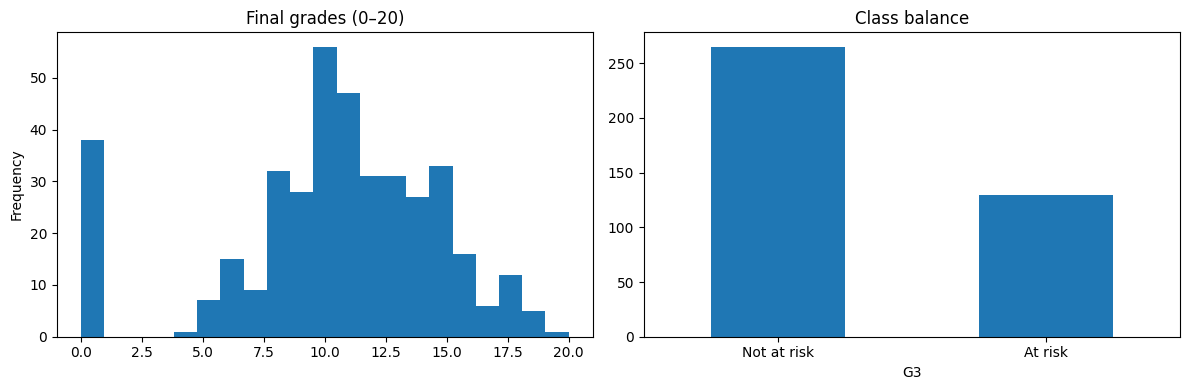

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
df.G3.plot(kind='hist',bins=21,ax=axs[0],title='Final grades (0–20)')
(df.G3<10).value_counts().plot(kind='bar',ax=axs[1],title='Class balance')
axs[1].set_xticklabels(['Not at risk' if not v else 'At risk' for v in (df.G3<10).value_counts().index],rotation=0)
plt.tight_layout();plt.show()

## Feature timing and leakage

In [4]:
early=feature_frame(df,'early');later=feature_frame(df,'grade_informed')
print('Early:',early.shape, 'G1 included?', 'G1' in early, 'G3 included?', 'G3' in early)
print('Grade-informed:',later.shape, 'G1 included?', 'G1' in later, 'G3 included?', 'G3' in later)
display(df[['studytime','failures','absences','G1','G2','G3']].corr())

Early: (395, 30) G1 included? False G3 included? False
Grade-informed: (395, 32) G1 included? True G3 included? False


,studytime,failures,absences,G1,G2,G3
studytime,1.000000,-0.173563,-0.062700,0.160612,0.135880,0.097820
failures,-0.173563,1.000000,0.063726,-0.354718,-0.355896,-0.360415
absences,-0.062700,0.063726,1.000000,-0.031003,-0.031777,0.034247
G1,0.160612,-0.354718,-0.031003,1.000000,0.852118,0.801468
G2,0.135880,-0.355896,-0.031777,0.852118,1.000000,0.904868
G3,0.097820,-0.360415,0.034247,0.801468,0.904868,1.000000


**Reflection:** G1 and G2 may improve late prediction, but they are unavailable early. G3 is always the target and must never be used as input.